<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/udlbook/Ch10_5_Convolutional_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import random
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

**Why are different batch sizes used for training and testing?**
- Training (Batch Size = 64): A smaller batch size is used because training requires both forward and backward passes, as well as gradient computation and weight updates. This helps reduce memory consumption.
- Testing (Batch Size = 1000): A larger batch size can be used because testing only requires forward passes. No gradients or weight updates are needed. Therefore, more samples can be processed simultaneously, reducing the number of iterations and computational overhead.

> **Important:** Using different batch sizes does not normally affect the final test accuracy. It mainly affects

In [2]:
batch_size_train = 64
batch_size_test = 1000

In [3]:
myDir = '/files/'

## Loading the Training Dataset

- **MNIST Dataset:** Loads the MNIST training dataset (`train=True`).
- **ToTensor():** Converts the images into PyTorch tensors and scales pixel values to the range [0, 1].
- **Normalize():** Normalizes the images using the MNIST mean (0.1307) and standard deviation (0.3081).
- **DataLoader:** Creates batches of 64 images (`batch_size=batch_size_train`).
- **shuffle=True:** Randomly shuffles the training data at the beginning of each epoch to improve training and prevent the model from learning the order of samples.

In [4]:
train_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST(myDir, train=True, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize((0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_train, shuffle=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 401kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.74MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.78MB/s]


## Loading the Test Dataset

- **MNIST Dataset:** Loads the MNIST test dataset (`train=False`).
- **ToTensor():** Converts the images into PyTorch tensors and scales pixel values to the range [0, 1].
- **Normalize():** Normalizes the images using the MNIST mean (0.1307) and standard deviation (0.3081), ensuring consistency with the training data.
- **DataLoader:** Creates batches of 1000 images (`batch_size=batch_size_test`).
- **shuffle=True:** Randomly shuffles the test data. Since the model is only evaluated and not trained on this dataset, shuffling does not affect the evaluation results.

In [5]:
test_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST(myDir, train=False, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_test, shuffle=True)

## Visualizing Sample Images from the Test Dataset

- **enumerate(test_loader):** Creates an iterator that provides both the batch index and the data from the test DataLoader.
- **next(examples):** Retrieves the first batch of test data, including images (`example_data`) and their corresponding labels (`example_targets`).
- **plt.figure():** Creates a new figure for visualization.
- **for loop:** Iterates over the first 6 images in the batch.
- **plt.subplot(2, 3, i+1):** Arranges the images in a grid with 2 rows and 3 columns.
- **plt.tight_layout():** Adjusts the spacing between subplots to prevent overlapping.
- **plt.imshow():** Displays each image in grayscale (`cmap='gray'`) without interpolation.
- **plt.title():** Displays the ground truth label (actual digit) above each image.
- **plt.xticks([]), plt.yticks([]):** Removes the axis tick marks for a cleaner visualization.
- **plt.show():** Displays the final figure.

**Note:** This cell visualizes 6 sample images from the test dataset along with their actual labels (Ground Truth).

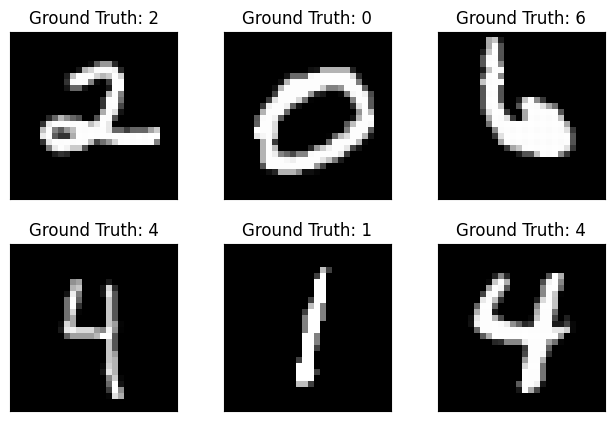

In [6]:
examples = enumerate(test_loader)
batch_idx, (example_data, example_targets) = next(examples)

fig = plt.figure()
for i in range(6):
  plt.subplot(2,3,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Ground Truth: {}".format(example_targets[i]))
  plt.xticks([])
  plt.yticks([])
plt.show()

## Defining the Convolutional Neural Network (CNN)

The network is defined using a custom class that inherits from `nn.Module`, rather than using `nn.Sequential`.

- **`__init__()`**: Defines and initializes the network layers and their parameters.
- **`forward()`**: Defines the sequence of operations performed on the input data.

**Network Architecture:**

1. **First Convolutional Layer:** Applies a valid convolution with a 5×5 kernel, transforming 1 input channel into 10 output channels.
2. **First Max Pooling:** Reduces the spatial dimensions using a 2×2 pooling window.
3. **ReLU Activation:** Introduces non-linearity.
4. **Second Convolutional Layer:** Applies a valid convolution with a 5×5 kernel, transforming 10 input channels into 20 output channels.
5. **Dropout2d:** Randomly drops entire feature channels during training to help prevent overfitting.
6. **Second Max Pooling:** Further reduces the spatial dimensions using a 2×2 pooling window.
7. **ReLU Activation:** Applies another non-linear activation.
8. **Flatten:** Converts the feature maps into a one-dimensional vector.
9. **First Fully Connected Layer:** Maps the 320 input features to 50 neurons.
10. **ReLU Activation:** Introduces non-linearity.
11. **Second Fully Connected Layer:** Maps the 50 features to 10 output values, representing the 10 MNIST digit classes.
12. **Log-Softmax:** Converts the output values into log-probabilities for classification.

**Output Dimensions:**

Since the input MNIST images have dimensions of 28×28 pixels, the output dimensions after each operation are:

| Layer / Operation | Output Shape |
|---|---|
| Input Image | 1 × 28 × 28 |
| Conv1 (5×5) | 10 × 24 × 24 |
| Max Pooling (2×2) | 10 × 12 × 12 |
| Conv2 (5×5) | 20 × 8 × 8 |
| Max Pooling (2×2) | 20 × 4 × 4 |
| Flatten | 320 |
| Fully Connected (FC1) | 50 |
| Fully Connected (FC2) | 10 |

**Calculating the Input Size of the First Fully Connected Layer:**

After the second convolution and max pooling operations, the feature maps have dimensions of 20 × 4 × 4. Therefore, the flattened feature vector contains:

$
20 \times 4 \times 4 = 320
$

This is why the first fully connected layer is defined as `nn.Linear(320, 50)`.

The final output consists of 10 log-probabilities, corresponding to the 10 digit classes (0–9).

In [7]:
from os import X_OK

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        # First convolutional layer: 1 input channel, 10 output channels
        self.conv1 = nn.Conv2d(1, 10, kernel_size=5)

        # Second convolutional layer: 10 input channels, 20 output channels
        self.conv2 = nn.Conv2d(10, 20, kernel_size=5)

        # Dropout for convolutional layers
        self.drop = nn.Dropout2d()

        # Fully connected layers
        self.fc1 = nn.Linear(320, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x):
        x = F.max_pool2d(self.conv1(x), 2)
        x = F.relu(x)

        x = F.max_pool2d(self.drop(self.conv2(x)), 2)
        x = F.relu(x)

        x = x.flatten(1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        x = F.log_softmax(x, dim=1)

        return x

## Weight Initialization

This function defines a custom weight initialization method for the network.

- **`isinstance(layer_in, nn.Linear)`**: Checks whether the current layer is a fully connected (Linear) layer.
- **`nn.init.kaiming_uniform_()`**: Initializes the weights using Kaiming Uniform initialization, which is designed to work well with ReLU activation functions and helps maintain stable signal propagation during training.
- **`layer_in.bias.data.fill_(0.0)`**: Initializes all bias values of the Linear layer to zero.

**Note:** This initialization function only applies to fully connected (`nn.Linear`) layers. Convolutional layers are not affected.

In [8]:
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

## Model Initialization and Optimizer Setup

- **`Net().to(device)`**: Creates an instance of the neural network and moves it to the specified device (CPU or GPU).
- **`model.apply(weights_init)`**: Applies the custom weight initialization function to all layers of the network. In this case, Kaiming Uniform initialization is applied to fully connected layers, and their biases are initialized to zero.
- **`optim.SGD()`**: Defines the Stochastic Gradient Descent (SGD) optimizer to update the network parameters during training.

**Optimizer Parameters:**
- **`model.parameters()`**: Provides all trainable parameters of the network (weights and biases).
- **`lr=0.01`**: Sets the learning rate, which controls the step size of parameter updates.
- **`momentum=0.5`**: Adds a fraction of the previous update to the current update to help accelerate convergence and reduce oscillations during optimization.

In [9]:
model = Net().to(device)

model.apply(weights_init)

optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)

## Training Function

This function defines one complete training epoch, during which the model processes the entire training dataset in batches and updates its parameters.

- **`model.train()`**: Sets the model to training mode, enabling training-specific layers such as Dropout.
- **`enumerate(train_loader)`**: Iterates over the training dataset batch by batch, providing the batch index, input images (`data`), and their corresponding labels (`target`).
- **`data.to(device)` and `target.to(device)`**: Move the input data and labels to the specified device (CPU or GPU).
- **`optimizer.zero_grad()`**: Clears the gradients from the previous iteration to prevent them from accumulating.
- **`model(data)`**: Performs a forward pass through the network and generates the predicted log-probabilities.
- **`F.nll_loss(output, target)`**: Calculates the Negative Log-Likelihood Loss by comparing the model predictions with the actual labels.
- **`loss.backward()`**: Performs backpropagation and computes the gradients of the loss with respect to the model parameters.
- **`optimizer.step()`**: Updates the model parameters using the calculated gradients and the SGD optimizer.

**Progress Monitoring:**

- **`if batch_idx % 10 == 0`**: Prints the training progress every 10 batches.
- **`batch_idx * len(data)`**: Calculates the number of samples processed so far.
- **`len(train_loader.dataset)`**: Returns the total number of training samples.
- **`loss.item()`**: Extracts the loss value as a Python number for display.

> **Note:** One epoch is completed when the model has processed all batches in the training dataset. The optimizer updates the model parameters after every batch.

In [10]:
def train(epoch):

  model.train()

  for batch_idx, (data, target) in enumerate(train_loader):
    data = data.to(device)
    target = target.to(device)
    optimizer.zero_grad()
    output = model(data)
    loss = F.nll_loss(output, target)
    loss.backward()
    optimizer.step()

    if batch_idx % 10 == 0:
      print('Train Epoch: {} [{}/{}]\tLoss: {:.6f}'.format(
        epoch, batch_idx * len(data), len(train_loader.dataset), loss.item()))

## Testing and Model Evaluation

This function evaluates the trained model on the test dataset without updating its parameters. It calculates the average test loss and classification accuracy.

- **`model.eval()`**: Switches the model to evaluation mode, disabling training-specific behavior such as Dropout.
- **`test_loss = 0`**: Initializes the total test loss.
- **`correct = 0`**: Initializes the counter for correctly classified samples.
- **`torch.no_grad()`**: Disables gradient calculation during testing, reducing memory consumption and computational overhead.
- **`for data, target in test_loader`**: Iterates over the test dataset in batches, retrieving input images and their corresponding ground truth labels.
- **`data.to(device)` and `target.to(device)`**: Move the images and labels to the specified device (CPU or GPU).
- **`model(data)`**: Performs a forward pass and generates the predicted log-probabilities.
- **`F.nll_loss(output, target, reduction='sum')`**: Calculates the sum of the Negative Log-Likelihood Loss for all samples in the current batch. The result is added to the total test loss.
- **`pred = output.data.max(1, keepdim=True)[1]`**: Finds the predicted class with the highest log-probability for each image.
- **`pred.eq(target.data.view_as(pred)).sum()`**: Compares the predicted labels with the actual labels and counts the correct predictions.

**Performance Calculation:**

- **`test_loss /= len(test_loader.dataset)`**: Calculates the average loss per test sample.
- **Accuracy:** Computes the percentage of correctly classified images by dividing the number of correct predictions by the total number of test samples and multiplying by 100.

>**Note:** Unlike the training function, the testing function does not perform backpropagation or update the model parameters. It only measures how well the trained model performs on unseen data.

In [11]:
def test():
  model.eval()
  test_loss = 0
  correct = 0
  with torch.no_grad():
    for data, target in test_loader:
      data = data.to(device)
      target = target.to(device)
      output = model(data)
      test_loss += F.nll_loss(output, target, size_average=False).item()
      pred = output.data.max(1, keepdim=True)[1]
      correct += pred.eq(target.data.view_as(pred)).sum()
  test_loss /= len(test_loader.dataset)
  print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
    test_loss, correct, len(test_loader.dataset),
    100. * correct / len(test_loader.dataset)))

## Running the Training and Testing Process

- **`test()`**: Evaluates the model before training begins to establish its initial performance on the test dataset.
- **`n_epochs = 3`**: Sets the total number of training epochs to 3.
- **`range(1, n_epochs + 1)`**: Iterates through the epochs, starting from 1 and ending at 3.
- **`train(epoch)`**: Trains the model for one epoch using the training dataset and updates its parameters.
- **`test()`**: Evaluates the model on the test dataset after each training epoch, calculating the average test loss and classification accuracy.

**Note:** The initial `test()` call provides a baseline for evaluating the model's performance before training. Running `test()` after each epoch allows us to monitor how the model's performance changes as training progresses.

In [12]:
test()

n_epochs = 3
for epoch in range(1, n_epochs + 1):
  train(epoch)
  test()

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:3236: UserWarning: size_average and reduce args will be deprecated, please use reduction='sum' instead.
  reduction = _Reduction.legacy_get_string(size_average, reduce)



Test set: Avg. loss: 2.5607, Accuracy: 469/10000 (5%)

Train Epoch: 1 [0/60000]	Loss: 2.824192
Train Epoch: 1 [640/60000]	Loss: 2.278081
Train Epoch: 1 [1280/60000]	Loss: 2.219177
Train Epoch: 1 [1920/60000]	Loss: 2.132550
Train Epoch: 1 [2560/60000]	Loss: 1.971396
Train Epoch: 1 [3200/60000]	Loss: 1.730651
Train Epoch: 1 [3840/60000]	Loss: 1.549335
Train Epoch: 1 [4480/60000]	Loss: 1.364092
Train Epoch: 1 [5120/60000]	Loss: 1.240937
Train Epoch: 1 [5760/60000]	Loss: 0.982046
Train Epoch: 1 [6400/60000]	Loss: 0.850519
Train Epoch: 1 [7040/60000]	Loss: 0.806344
Train Epoch: 1 [7680/60000]	Loss: 0.738300
Train Epoch: 1 [8320/60000]	Loss: 0.850675
Train Epoch: 1 [8960/60000]	Loss: 0.680972
Train Epoch: 1 [9600/60000]	Loss: 0.901841
Train Epoch: 1 [10240/60000]	Loss: 0.570054
Train Epoch: 1 [10880/60000]	Loss: 0.588281
Train Epoch: 1 [11520/60000]	Loss: 0.814469
Train Epoch: 1 [12160/60000]	Loss: 0.613669
Train Epoch: 1 [12800/60000]	Loss: 0.692150
Train Epoch: 1 [13440/60000]	Loss: 0.841

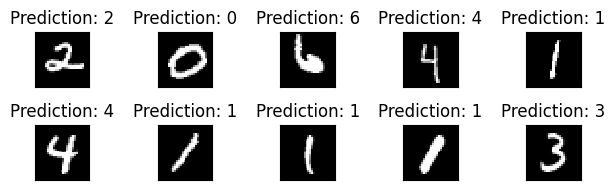

In [13]:
output = model(example_data)

fig = plt.figure()
for i in range(10):
  plt.subplot(5,5,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Prediction: {}".format(
    output.data.max(1, keepdim=True)[1][i].item()))
  plt.xticks([])
  plt.yticks([])
plt.show()